In [2]:
import os
import tarfile
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split

In [3]:
archive_path = "HASYv2.tar.bz2"
extract_path = "HASYv2"

if not os.path.exists(extract_path):

    print("Extracting HASYv2...")

    with tarfile.open(archive_path, "r:bz2") as tar:
        tar.extractall(extract_path)

    print("Extraction complete!")

else:
    print("Dataset already extracted.")

Dataset already extracted.


In [4]:
symbols_path = os.path.join(
    extract_path,
    "symbols.csv"
)

symbols = pd.read_csv(symbols_path)

print("Number of classes:", len(symbols))

symbols.head()

Number of classes: 369


,symbol_id,latex,training_samples,test_samples
0,31,A,137,22
1,32,B,53,8
2,33,C,120,14
3,34,D,50,8
4,35,E,48,6


In [5]:
selected_symbols = [
    "0", "1", "2", "3", "4",
    "5", "6", "7", "8", "9",
    "+", "-",
    "x", "y", "z",
    r"\times",
    r"\div",
    r"\sqrt{}",
    r"\pi"
]

print("Selected classes:", len(selected_symbols))
print(selected_symbols)

Selected classes: 19
['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '+', '-', 'x', 'y', 'z', '\\times', '\\div', '\\sqrt{}', '\\pi']


In [6]:
train_csv = os.path.join(
    extract_path,
    "classification-task",
    "fold-1",
    "train.csv"
)

test_csv = os.path.join(
    extract_path,
    "classification-task",
    "fold-1",
    "test.csv"
)

train_data = pd.read_csv(train_csv)
test_data = pd.read_csv(test_csv)

print("Original training images:", len(train_data))
print("Original testing images:", len(test_data))

Original training images: 151241
Original testing images: 16992


In [8]:
train_data = train_data[
    train_data["latex"].isin(selected_symbols)
].copy()

test_data = test_data[
    test_data["latex"].isin(selected_symbols)
].copy()

print("Training images:", len(train_data))
print("Testing images:", len(test_data))
print("Classes:", train_data["latex"].nunique())

Training images: 5184
Testing images: 583
Classes: 19


In [9]:
classes = sorted(selected_symbols)

label_to_number = {
    symbol: i
    for i, symbol in enumerate(classes)
}

number_to_label = {
    i: symbol
    for symbol, i in label_to_number.items()
}

print(label_to_number)

{'+': 0, '-': 1, '0': 2, '1': 3, '2': 4, '3': 5, '4': 6, '5': 7, '6': 8, '7': 9, '8': 10, '9': 11, '\\div': 12, '\\pi': 13, '\\sqrt{}': 14, '\\times': 15, 'x': 16, 'y': 17, 'z': 18}


In [10]:
train_data["label"] = train_data["latex"].map(label_to_number)

test_data["label"] = test_data["latex"].map(label_to_number)

In [11]:
train_data, val_data = train_test_split(
    train_data,
    test_size=0.10,
    random_state=42,
    stratify=train_data["label"]
)

print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Testing:", len(test_data))

Training: 4665
Validation: 519
Testing: 583


In [12]:
train_transform = transforms.Compose([
    transforms.RandomRotation(10),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.1, 0.1)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        (0.5,),
        (0.5,)
    )
])

In [13]:
test_transform = transforms.Compose([
    transforms.ToTensor(),

    transforms.Normalize(
        (0.5,),
        (0.5,)
    )
])

In [14]:
class HASYDataset(Dataset):

    def __init__(self, data, image_folder, transform=None):

        self.data = data.reset_index(drop=True)
        self.image_folder = image_folder
        self.transform = transform

    def __len__(self):

        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        image_name = os.path.basename(row["path"])

        image_path = os.path.join(
            self.image_folder,
            image_name
        )

        image = Image.open(
            image_path
        ).convert("L")

        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, label

In [16]:
image_folder = os.path.join(
    extract_path,
    "hasy-data"
)

train_dataset = HASYDataset(
    train_data,
    image_folder,
    train_transform
)

val_dataset = HASYDataset(
    val_data,
    image_folder,
    test_transform
)

test_dataset = HASYDataset(
    test_data,
    image_folder,
    test_transform
)

In [17]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

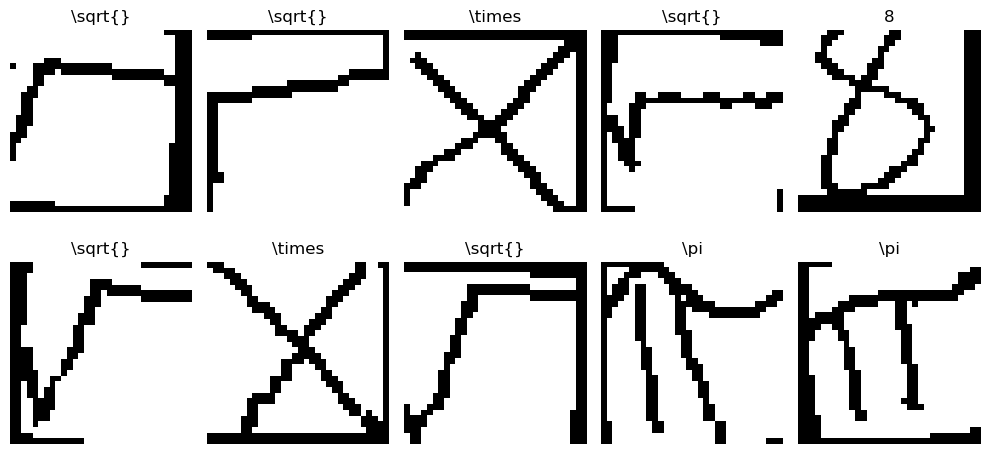

In [18]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    image = images[i].squeeze()

    plt.imshow(image, cmap="gray")

    symbol = number_to_label[
        labels[i].item()
    ]

    plt.title(symbol)

    plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
class MathCNN(nn.Module):

    def __init__(self, num_classes):

        super().__init__()

        # First convolution
        self.conv1 = nn.Conv2d(
            1, 32,
            kernel_size=3,
            padding=1
        )

        # Second convolution
        self.conv2 = nn.Conv2d(
            32, 64,
            kernel_size=3,
            padding=1
        )

        self.relu = nn.ReLU()

        self.pool = nn.MaxPool2d(
            kernel_size=2
        )

        # 32x32 → 16x16 → 8x8
        self.fc1 = nn.Linear(
            64 * 8 * 8,
            128
        )

        self.fc2 = nn.Linear(
            128,
            num_classes
        )

    def forward(self, x):

        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)

        x = torch.flatten(x, 1)

        x = self.fc1(x)
        x = self.relu(x)

        x = self.fc2(x)

        return x

In [20]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

model = MathCNN(
    num_classes=len(classes)
).to(device)

print("Device:", device)
print("Number of classes:", len(classes))

Device: cpu
Number of classes: 19


In [21]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [22]:
epochs = 10

for epoch in range(epochs):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Remove old gradients
        optimizer.zero_grad()

        # Prediction
        outputs = model(images)

        # Calculate loss
        loss = criterion(
            outputs,
            labels
        )

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item()

        # Find predicted class
        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()

    accuracy = (
        100 * correct / total
    )

    average_loss = (
        total_loss / len(train_loader)
    )

    print(
        f"Epoch {epoch + 1}/{epochs} "
        f"| Loss: {average_loss:.4f} "
        f"| Accuracy: {accuracy:.2f}%"
    )

Epoch 1/10 | Loss: 1.1346 | Accuracy: 69.35%
Epoch 2/10 | Loss: 0.4672 | Accuracy: 87.42%
Epoch 3/10 | Loss: 0.3165 | Accuracy: 91.92%
Epoch 4/10 | Loss: 0.2667 | Accuracy: 92.90%
Epoch 5/10 | Loss: 0.2321 | Accuracy: 93.89%
Epoch 6/10 | Loss: 0.2073 | Accuracy: 94.79%
Epoch 7/10 | Loss: 0.1840 | Accuracy: 95.11%
Epoch 8/10 | Loss: 0.1670 | Accuracy: 95.39%
Epoch 9/10 | Loss: 0.1530 | Accuracy: 95.93%
Epoch 10/10 | Loss: 0.1499 | Accuracy: 95.93%


In [23]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()

test_accuracy = (
    100 * correct / total
)

print(
    f"Test Accuracy: "
    f"{test_accuracy:.2f}%"
)

Test Accuracy: 95.20%


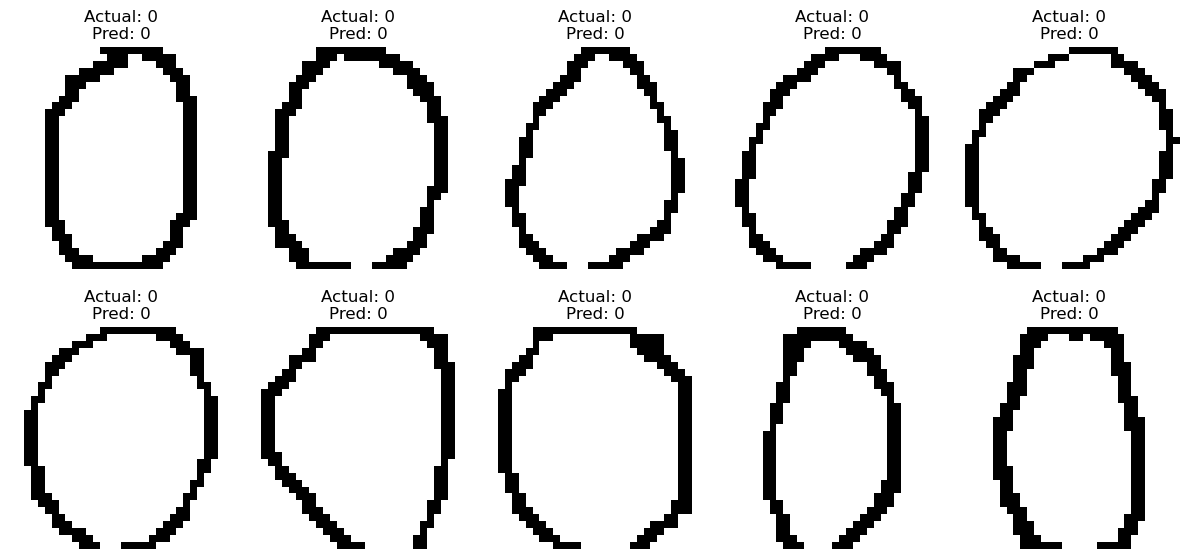

In [24]:
images, labels = next(iter(test_loader))

images = images.to(device)

model.eval()

with torch.no_grad():

    outputs = model(images)

    _, predictions = torch.max(
        outputs,
        1
    )

plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    image = images[i].cpu().squeeze()

    plt.imshow(
        image,
        cmap="gray"
    )

    actual = number_to_label[
        labels[i].item()
    ]

    predicted = number_to_label[
        predictions[i].item()
    ]

    plt.title(
        f"Actual: {actual}\n"
        f"Pred: {predicted}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

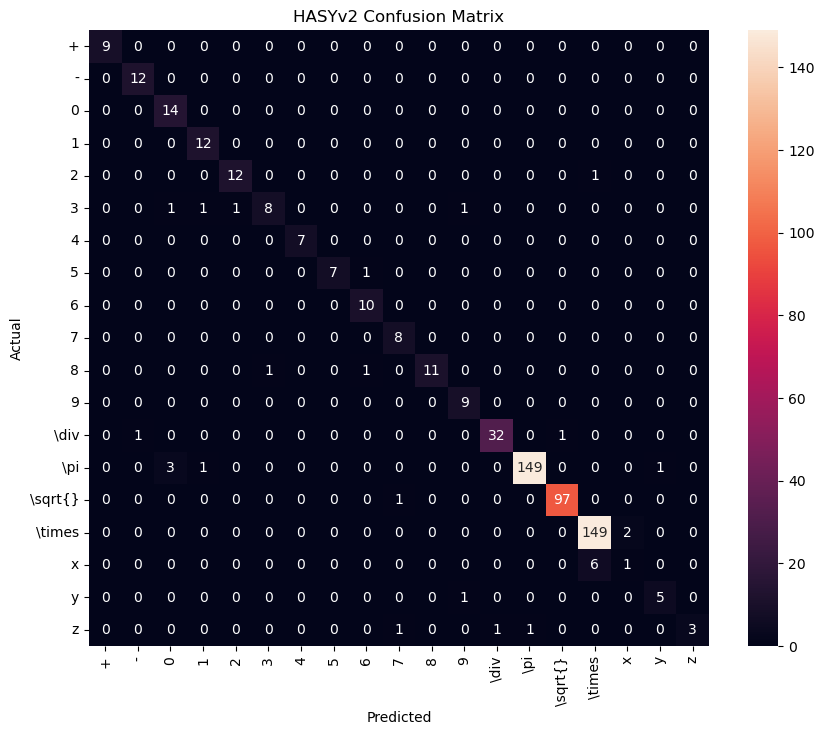

In [25]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

all_labels = []
all_predictions = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, predictions = torch.max(
            outputs,
            1
        )

        all_labels.extend(
            labels.numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("HASYv2 Confusion Matrix")

plt.show()

In [26]:
torch.save(
    model.state_dict(),
    "HASYv2_math_CNN.pth"
)

print("Model saved successfully!")

Model saved successfully!
